# **CASE STUDY 2**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_excel("EastWestAirlines.xlsx", sheet_name="data")

In [ ]:
print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())

Dataset shape: (3999, 12)

First five records:


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [ ]:
print("\nColumn information:")
df.info()


Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


In [ ]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64


In [ ]:

print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


In [ ]:
print("\nStatistical summary:")
display(df.describe().T)


Statistical summary:


,count,mean,std,min,25%,50%,75%,max
ID#,3999.0,2014.819455,1160.764358,1.0,1010.5,2016.0,3020.5,4021.0
Balance,3999.0,73601.327582,100775.664958,0.0,18527.5,43097.0,92404.0,1704838.0
Qual_miles,3999.0,144.114529,773.663804,0.0,0.0,0.0,0.0,11148.0
cc1_miles,3999.0,2.059515,1.376919,1.0,1.0,1.0,3.0,5.0
cc2_miles,3999.0,1.014504,0.147650,1.0,1.0,1.0,1.0,3.0
cc3_miles,3999.0,1.012253,0.195241,1.0,1.0,1.0,1.0,5.0
Bonus_miles,3999.0,17144.846212,24150.967826,0.0,1250.0,7171.0,23800.5,263685.0
Bonus_trans,3999.0,11.601900,9.603810,0.0,3.0,12.0,17.0,86.0
Flight_miles_12mo,3999.0,460.055764,1400.209171,0.0,0.0,0.0,311.0,30817.0
Flight_trans_12,3999.0,1.373593,3.793172,0.0,0.0,0.0,1.0,53.0


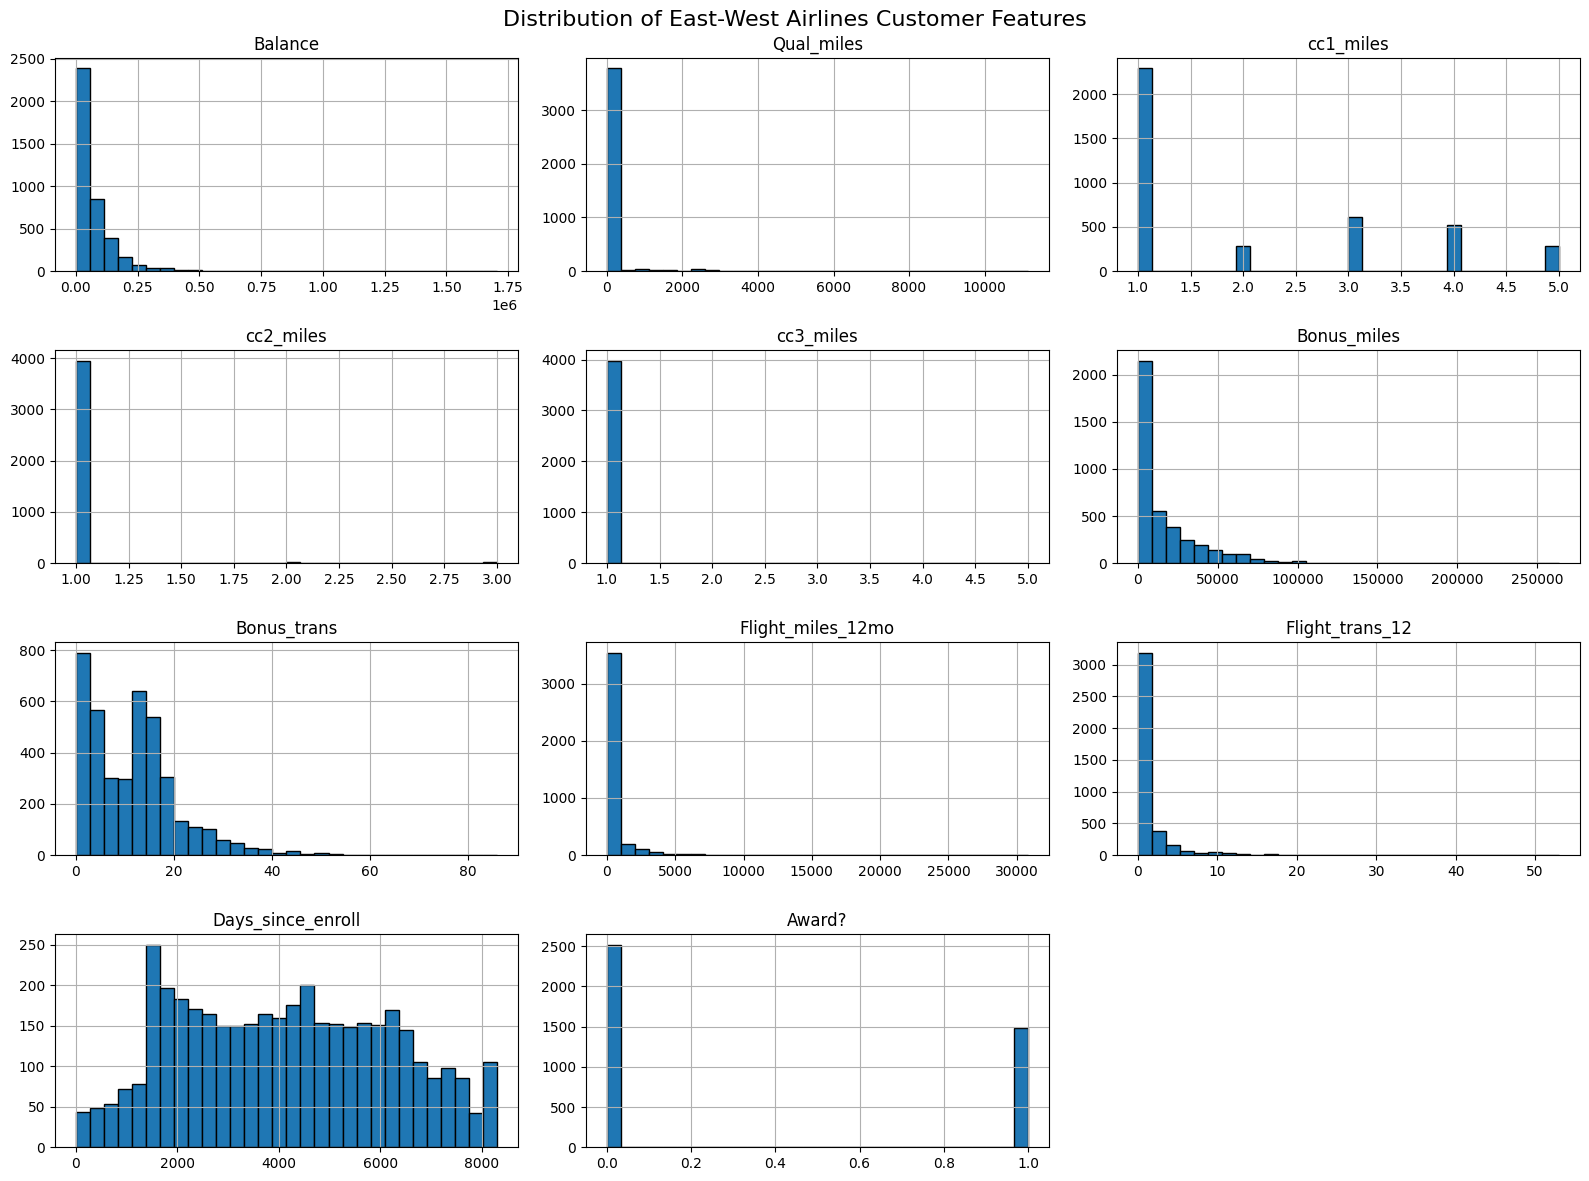

In [ ]:


features = df.drop(columns=["ID#"])
features.hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Distribution of East-West Airlines Customer Features",
             fontsize=16)
plt.tight_layout()
plt.show()


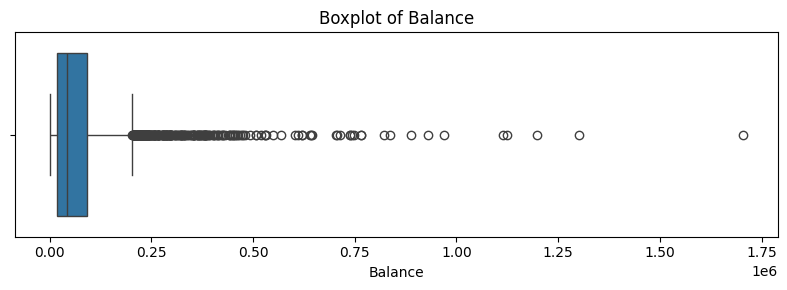

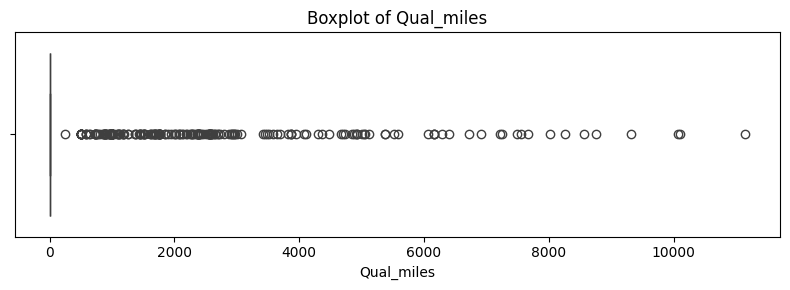

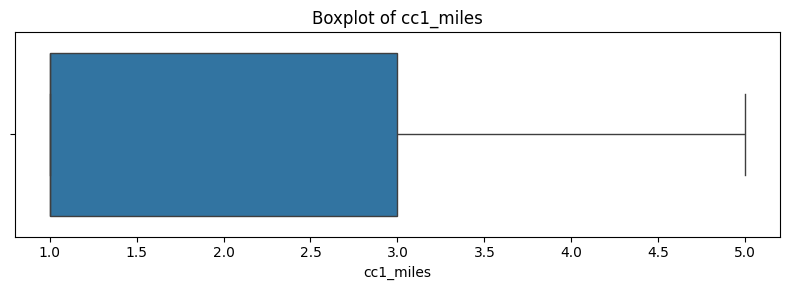

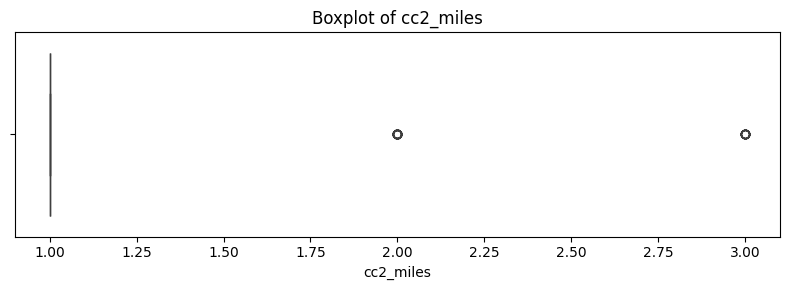

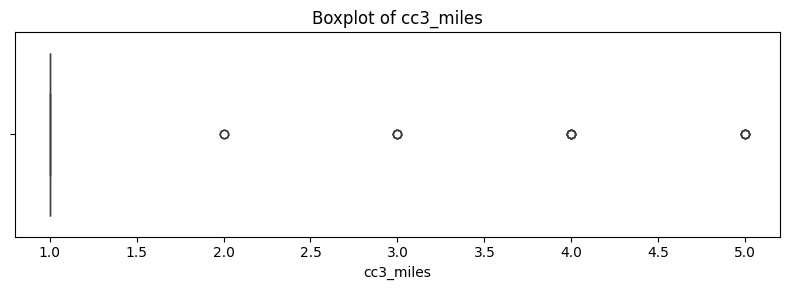

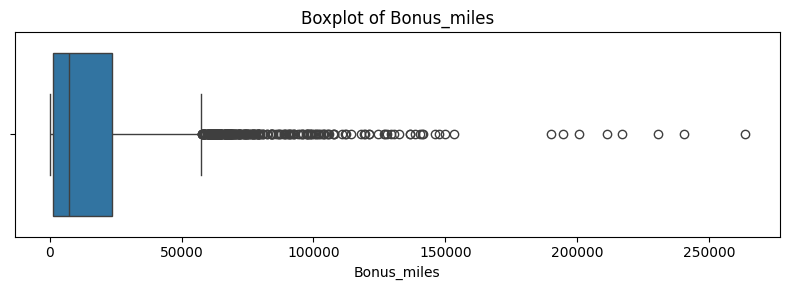

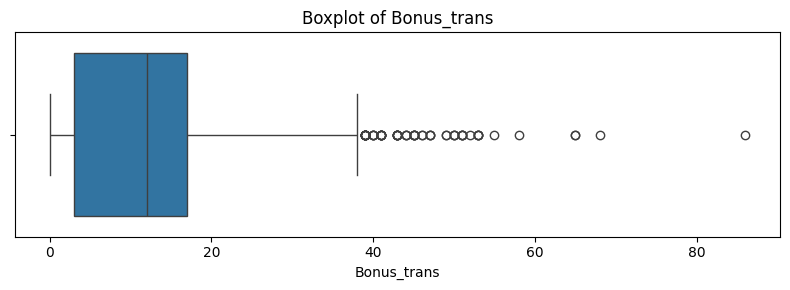

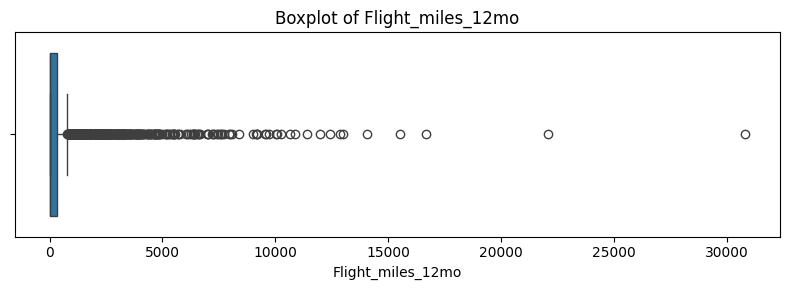

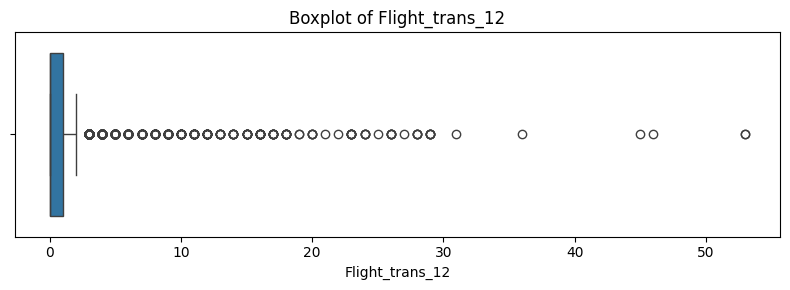

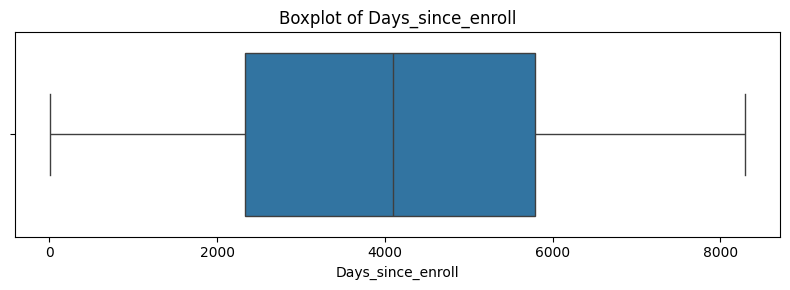

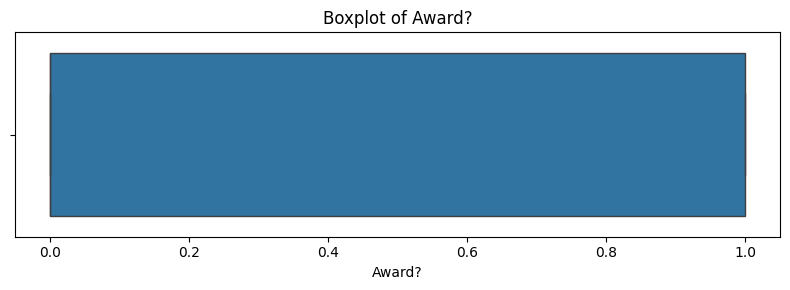

In [ ]:

for col in features.columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


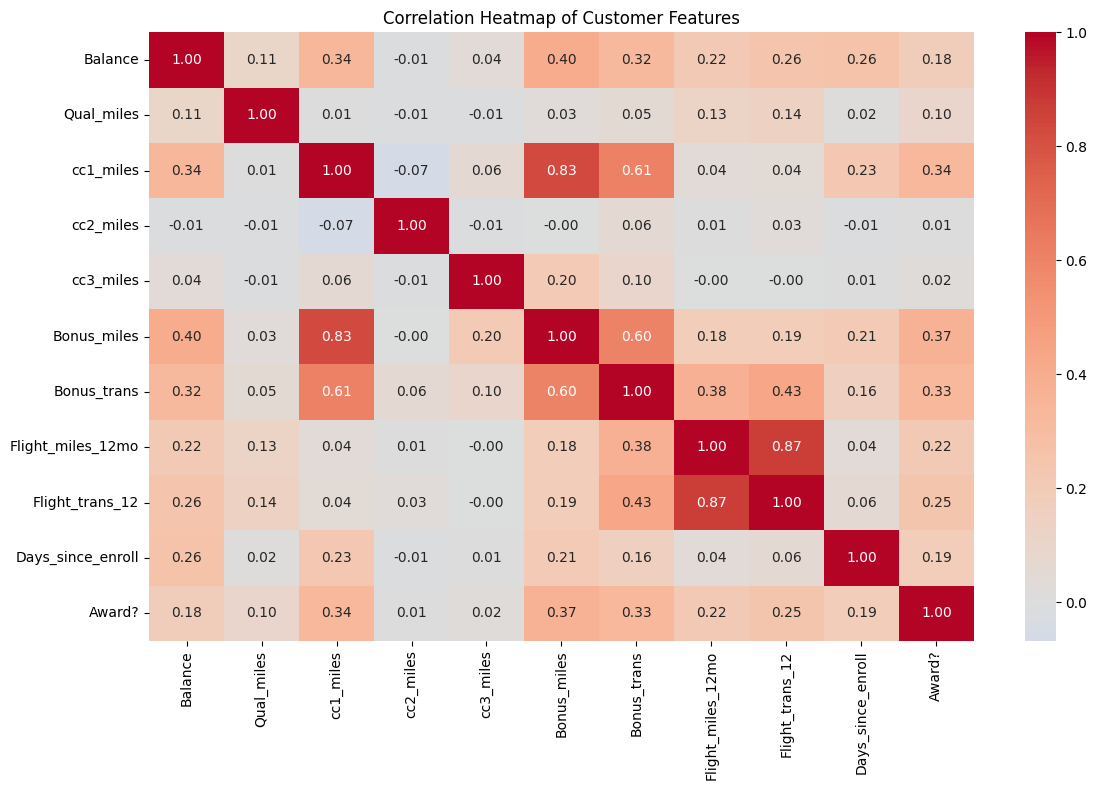

In [ ]:

plt.figure(figsize=(12, 8))

sns.heatmap(
    features.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Customer Features")
plt.tight_layout()
plt.show()


In [ ]:

print("Award flight indicator:")
print(df["Award?"].value_counts())

print("\nCredit card mileage categories:")
for col in ["cc1_miles", "cc2_miles", "cc3_miles"]:
    print(f"\n{col}")
    print(df[col].value_counts().sort_index())


Award flight indicator:
Award?
0    2518
1    1481
Name: count, dtype: int64

Credit card mileage categories:

cc1_miles
cc1_miles
1    2289
2     284
3     613
4     525
5     288
Name: count, dtype: int64

cc2_miles
cc2_miles
1    3956
2      28
3      15
Name: count, dtype: int64

cc3_miles
cc3_miles
1    3981
2       3
3       4
4       6
5       5
Name: count, dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler


In [ ]:

X = df.drop(columns=["ID#"])


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Original feature shape:", X.shape)
print("Scaled feature shape:", X_scaled.shape)


scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
display(scaled_df.head())


print("\nFeature means after scaling:")
print(scaled_df.mean().round(2))

Original feature shape: (3999, 11)
Scaled feature shape: (3999, 11)


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,-0.451141,-0.186299,-0.769578,-0.098242,-0.062767,-0.702786,-1.104065,-0.328603,-0.362168,1.395454,-0.766919
1,-0.539457,-0.186299,-0.769578,-0.098242,-0.062767,-0.701088,-0.999926,-0.328603,-0.362168,1.379957,-0.766919
2,-0.320031,-0.186299,-0.769578,-0.098242,-0.062767,-0.539253,-0.791649,-0.328603,-0.362168,1.411920,-0.766919
3,-0.583799,-0.186299,-0.769578,-0.098242,-0.062767,-0.689286,-1.104065,-0.328603,-0.362168,1.372208,-0.766919
4,0.239678,-0.186299,1.409471,-0.098242,-0.062767,1.083121,1.499394,1.154932,0.692490,1.363975,1.303918



Feature means after scaling:
Balance              0.0
Qual_miles           0.0
cc1_miles            0.0
cc2_miles            0.0
cc3_miles            0.0
Bonus_miles         -0.0
Bonus_trans         -0.0
Flight_miles_12mo    0.0
Flight_trans_12      0.0
Days_since_enroll    0.0
Award?               0.0
dtype: float64


In [ ]:

print("\nFeature standard deviations after scaling:")
print(scaled_df.std().round(2))


Feature standard deviations after scaling:
Balance              1.0
Qual_miles           1.0
cc1_miles            1.0
cc2_miles            1.0
cc3_miles            1.0
Bonus_miles          1.0
Bonus_trans          1.0
Flight_miles_12mo    1.0
Flight_trans_12      1.0
Days_since_enroll    1.0
Award?               1.0
dtype: float64


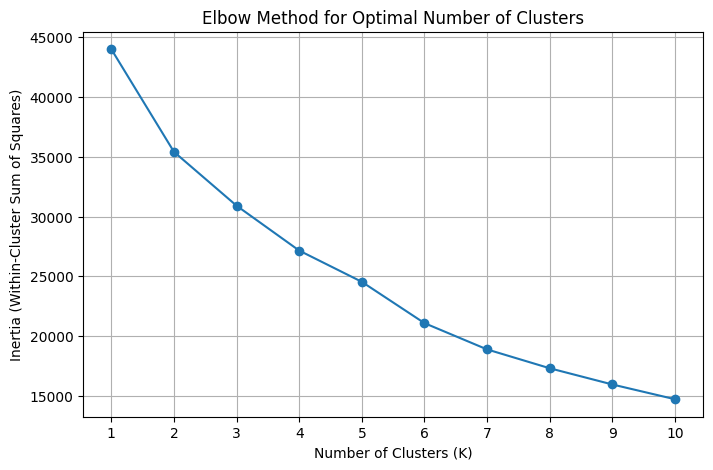

In [ ]:

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()


In [ ]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)


df["KMeans_Cluster"] = kmeans_labels


print("Customers in each cluster:")
print(df["KMeans_Cluster"].value_counts().sort_index())


sil_score = silhouette_score(X_scaled, kmeans_labels)
print("\nSilhouette Score:", round(sil_score, 4))
print("Inertia:", round(kmeans.inertia_, 2))


Customers in each cluster:
KMeans_Cluster
0      15
1    2543
2    1273
3     168
Name: count, dtype: int64

Silhouette Score: 0.3092
Inertia: 27154.33


,K,Inertia,Silhouette Score
0,2,35409.52,0.3254
1,3,30906.11,0.3111
2,4,27154.33,0.3092
3,5,24541.47,0.3189
4,6,21089.69,0.3334
5,7,18891.93,0.2837


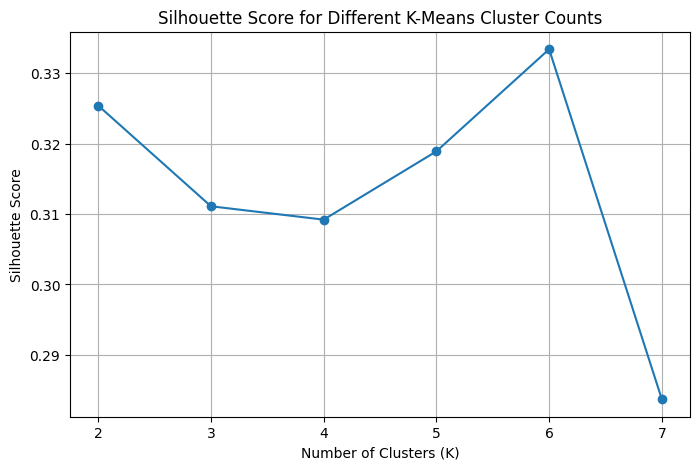

In [ ]:

from sklearn.metrics import silhouette_score

silhouette_results = []

for k in range(2, 8):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    silhouette_results.append({
        "K": k,
        "Inertia": round(model.inertia_, 2),
        "Silhouette Score": round(score, 4)
    })

silhouette_df = pd.DataFrame(silhouette_results)
display(silhouette_df)

plt.figure(figsize=(8, 5))
plt.plot(
    silhouette_df["K"],
    silhouette_df["Silhouette Score"],
    marker="o"
)
plt.title("Silhouette Score for Different K-Means Cluster Counts")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 8))
plt.grid(True)
plt.show()


In [ ]:


kmeans6 = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

labels6 = kmeans6.fit_predict(X_scaled)


df["KMeans_Cluster_6"] = labels6

print("Number of customers in each cluster:")
print(df["KMeans_Cluster_6"].value_counts().sort_index())

print("\nSilhouette Score:",
      round(silhouette_score(X_scaled, labels6), 4))


Number of customers in each cluster:
KMeans_Cluster_6
0    1253
1    2484
2     143
3      43
4      15
5      61
Name: count, dtype: int64

Silhouette Score: 0.3334


In [ ]:


profile_features = [
    col for col in df.columns
    if col not in ["ID#", "KMeans_Cluster", "KMeans_Cluster_6"]
]


cluster_medians = df.groupby("KMeans_Cluster_6")[
    profile_features
].median().round(2)

print("Median feature values for each cluster:")
display(cluster_medians)

cluster_means = df.groupby("KMeans_Cluster_6")[
    profile_features
].mean().round(2)

print("Mean feature values for each cluster:")
display(cluster_means)


Median feature values for each cluster:


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
KMeans_Cluster_6,,,,,,,,,,,
0,84674.0,0.0,4.0,1.0,1.0,33876.0,17.0,0.0,0.0,5009.0,1.0
1,27904.5,0.0,1.0,1.0,1.0,2299.5,5.0,0.0,0.0,3543.5,0.0
2,119214.0,0.0,1.0,1.0,1.0,19172.0,26.0,4673.0,15.0,4758.0,1.0
3,37300.0,0.0,1.0,2.0,1.0,11397.0,14.0,0.0,0.0,3726.0,0.0
4,108081.0,0.0,4.0,1.0,4.0,95598.0,30.0,0.0,0.0,4103.0,1.0
5,89112.0,4924.0,1.0,1.0,1.0,10550.0,13.0,500.0,1.0,3916.0,1.0


Mean feature values for each cluster:


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
KMeans_Cluster_6,,,,,,,,,,,
0,117306.66,60.54,3.71,1.00,1.00,39273.75,18.76,347.40,1.04,4896.24,0.65
1,43521.86,42.44,1.23,1.00,1.00,4610.95,6.83,198.17,0.62,3697.21,0.20
2,188155.66,464.57,2.24,1.00,1.00,32995.58,27.98,5739.69,16.55,4679.25,0.80
3,68876.58,23.26,1.14,2.35,1.00,14689.84,17.53,582.63,2.21,3968.93,0.40
4,138061.40,78.80,3.47,1.00,4.07,93927.87,28.07,506.67,1.60,4613.87,0.53
5,119660.49,5351.07,2.00,1.00,1.00,18683.48,12.23,963.64,2.87,3971.49,0.56


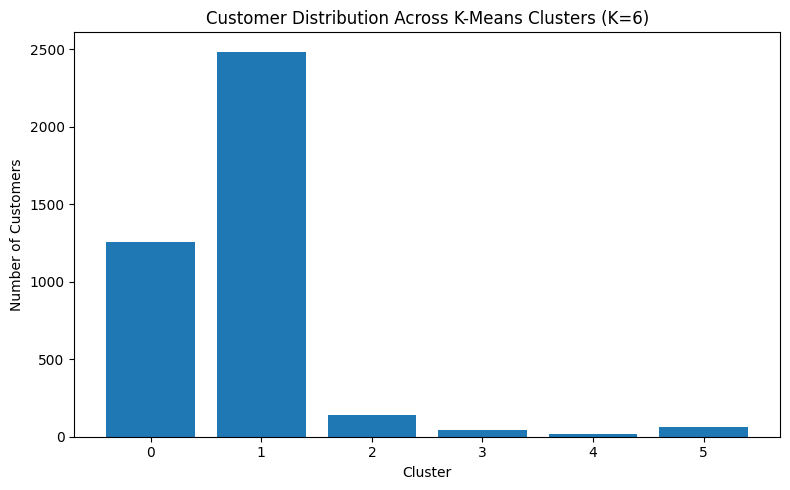

In [ ]:

cluster_counts = df["KMeans_Cluster_6"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)
plt.title("Customer Distribution Across K-Means Clusters (K=6)")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Apply hierarchical clustering
hierarchical = AgglomerativeClustering(
    n_clusters=6,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

# Store cluster assignments
df["Hierarchical_Cluster"] = hierarchical_labels

print("Customers in each hierarchical cluster:")
print(
    df["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)

# Evaluate clustering
hierarchical_silhouette = silhouette_score(
    X_scaled,
    hierarchical_labels
)

print("\nHierarchical Silhouette Score:",
      round(hierarchical_silhouette, 4))


Customers in each hierarchical cluster:
Hierarchical_Cluster
0    2446
1    1232
2     130
3      43
4      18
5     130
Name: count, dtype: int64

Hierarchical Silhouette Score: 0.3193


   K-Means  Hierarchical
0     1253          2446
1     2484          1232
2      143           130
3       43            43
4       15            18
5       61           130


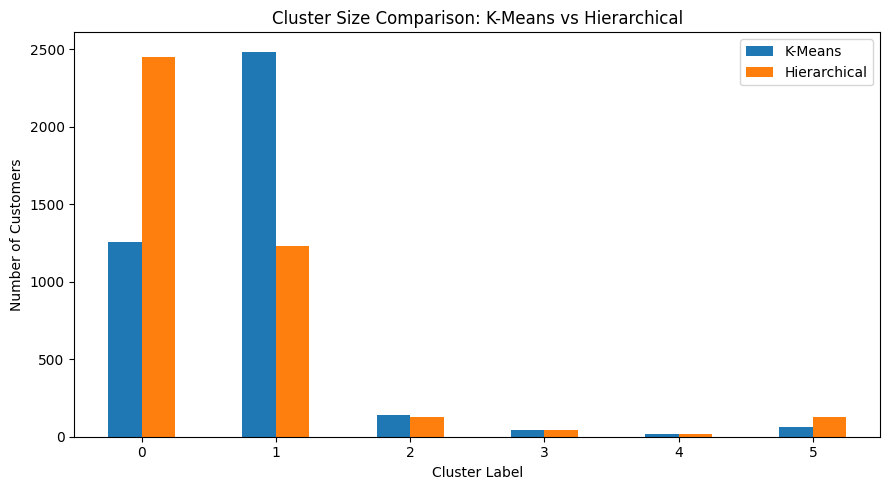

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "K-Means": df["KMeans_Cluster_6"].value_counts().sort_index(),
    "Hierarchical": df["Hierarchical_Cluster"].value_counts().sort_index()
}).fillna(0).astype(int)

print(comparison)

comparison.plot(kind="bar", figsize=(9, 5))
plt.title("Cluster Size Comparison: K-Means vs Hierarchical")
plt.xlabel("Cluster Label")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


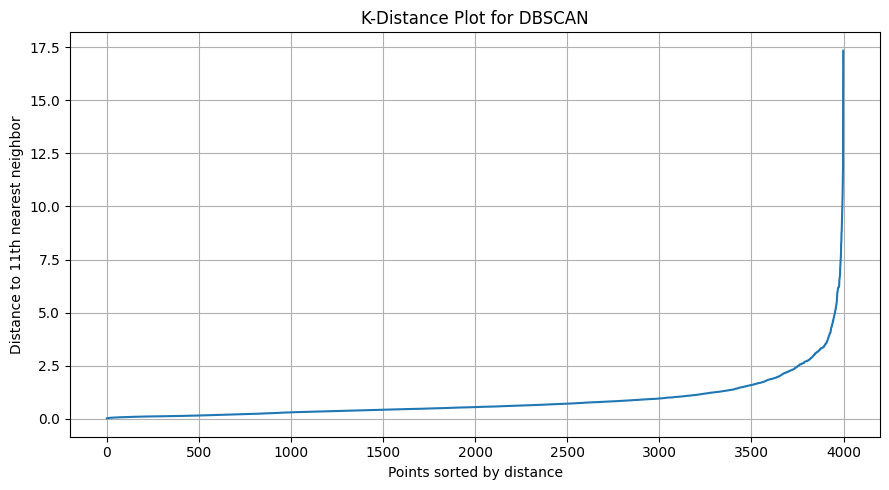

In [ ]:

from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Number of neighbors to examine
min_samples = 11

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Distance to the 11th nearest neighbor
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distances)
plt.title("K-Distance Plot for DBSCAN")
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.cluster import DBSCAN
import pandas as pd

dbscan = DBSCAN(eps=1.5, min_samples=11)
dbscan_labels = dbscan.fit_predict(X_scaled)

df["DBSCAN_Cluster"] = dbscan_labels

cluster_counts = df["DBSCAN_Cluster"].value_counts().sort_index()

print("DBSCAN cluster counts (label -1 means noise):")
print(cluster_counts)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))

print("\nNumber of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Noise percentage:", round(100 * n_noise / len(df), 2), "%")


DBSCAN cluster counts (label -1 means noise):
DBSCAN_Cluster
-1     379
 0    2396
 1    1209
 2      15
Name: count, dtype: int64

Number of clusters: 3
Number of noise points: 379
Noise percentage: 9.48 %


In [ ]:

from sklearn.metrics import silhouette_score

# Exclude noise points from this silhouette calculation
mask = dbscan_labels != -1
labels_without_noise = dbscan_labels[mask]
X_without_noise = X_scaled[mask]

if (
    len(set(labels_without_noise)) >= 2
    and len(set(labels_without_noise)) < len(labels_without_noise)
):
    score = silhouette_score(X_without_noise, labels_without_noise)
    print("Silhouette score excluding noise:", round(score, 4))
else:
    print("Silhouette score is not defined for this result.")

print("Noise points:", int(np.sum(~mask)))


Silhouette score excluding noise: 0.2983
Noise points: 379


In [ ]:

from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

results = []

for eps in [1.0, 1.25, 1.5, 1.75, 2.0]:
    labels = DBSCAN(
        eps=eps,
        min_samples=11
    ).fit_predict(X_scaled)

    non_noise = labels != -1
    labels_clean = labels[non_noise]
    X_clean = X_scaled[non_noise]

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_count = int(np.sum(labels == -1))

    if (
        n_clusters >= 2
        and len(set(labels_clean)) >= 2
        and len(set(labels_clean)) < len(labels_clean)
    ):
        sil = silhouette_score(X_clean, labels_clean)
    else:
        sil = np.nan

    results.append({
        "eps": eps,
        "clusters": n_clusters,
        "noise_points": noise_count,
        "noise_percent": round(100 * noise_count / len(labels), 2),
        "silhouette_excluding_noise": (
            round(sil, 4) if not np.isnan(sil) else np.nan
        )
    })

display(pd.DataFrame(results))


,eps,clusters,noise_points,noise_percent,silhouette_excluding_noise
0,1.00,2,698,17.45,0.3172
1,1.25,4,482,12.05,0.2880
2,1.50,3,379,9.48,0.2983
3,1.75,3,297,7.43,0.2914
4,2.00,3,240,6.00,0.2871


# **FINAL MODEL**

In [ ]:

from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

# K-Means and hierarchical scores on all customers
kmeans_sil = silhouette_score(X_scaled, labels6)
hierarchical_sil = silhouette_score(X_scaled, hierarchical_labels)

# DBSCAN score on non-noise customers
dbscan_mask = dbscan_labels != -1
dbscan_clean_labels = dbscan_labels[dbscan_mask]
dbscan_clean_X = X_scaled[dbscan_mask]

if (
    len(set(dbscan_clean_labels)) >= 2
    and len(set(dbscan_clean_labels)) < len(dbscan_clean_labels)
):
    dbscan_sil = silhouette_score(
        dbscan_clean_X,
        dbscan_clean_labels
    )
else:
    dbscan_sil = np.nan

evaluation = pd.DataFrame({
    "Algorithm": [
        "K-Means (K=6)",
        "Hierarchical (6 clusters)",
        "DBSCAN (eps=1.5, min_samples=11)"
    ],
    "Number of clusters": [
        len(set(labels6)),
        len(set(hierarchical_labels)),
        len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
    ],
    "Silhouette score": [
        kmeans_sil,
        hierarchical_sil,
        dbscan_sil
    ],
    "Noise points": [
        0,
        0,
        int(np.sum(dbscan_labels == -1))
    ]
})

display(evaluation.round(4))


,Algorithm,Number of clusters,Silhouette score,Noise points
0,K-Means (K=6),6,0.3334,0
1,Hierarchical (6 clusters),6,0.3193,0
2,"DBSCAN (eps=1.5, min_samples=11)",3,0.2983,379


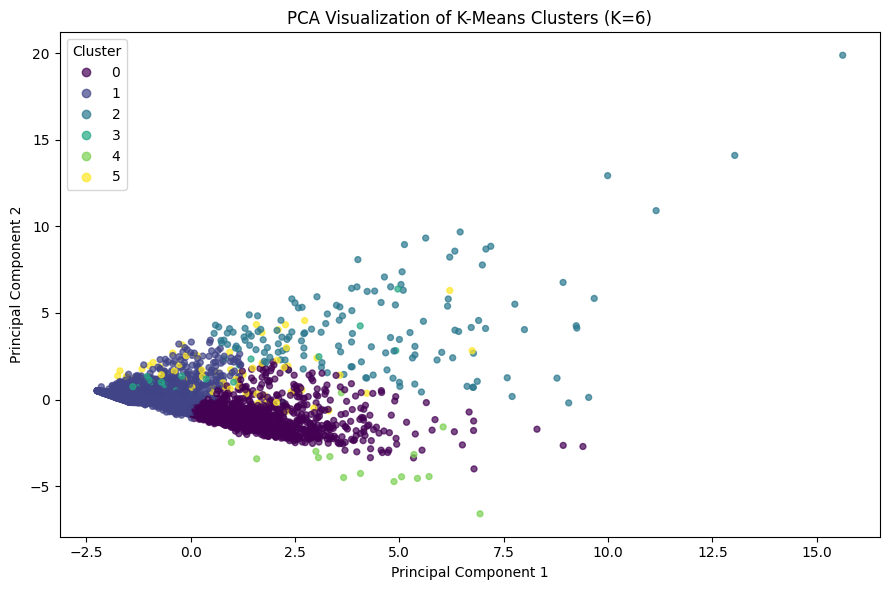

Variance explained by first two components: 0.4558


In [ ]:

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels6,
    cmap="viridis",
    s=18,
    alpha=0.7
)

plt.title("PCA Visualization of K-Means Clusters (K=6)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(
    *scatter.legend_elements(),
    title="Cluster"
)
plt.tight_layout()
plt.show()

print("Variance explained by first two components:",
      round(pca.explained_variance_ratio_.sum(), 4))


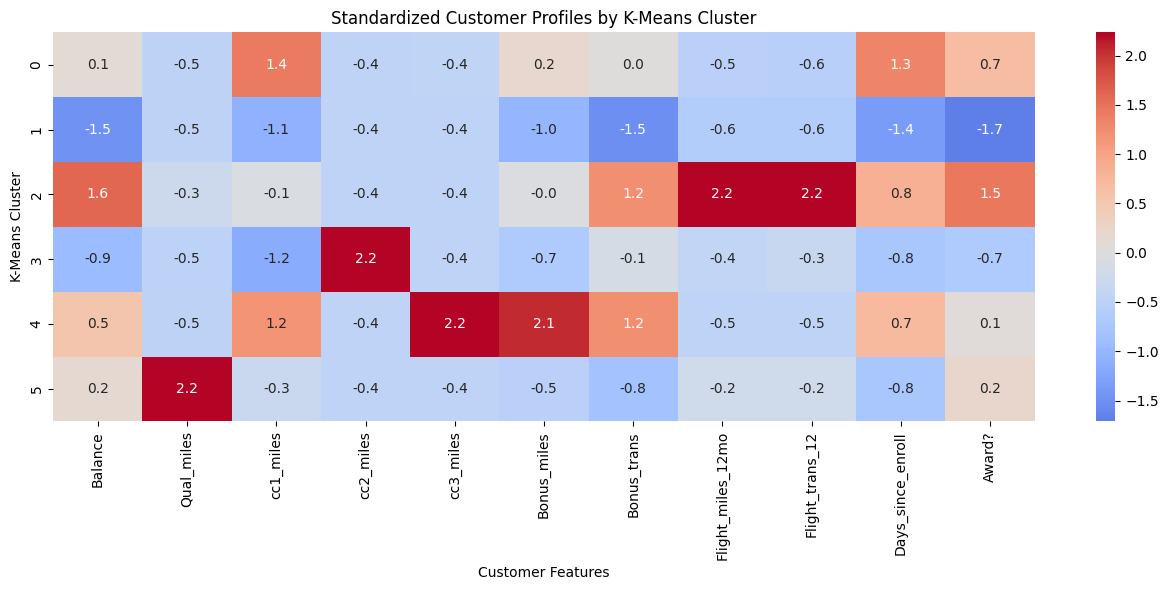

In [ ]:

import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Mean values for each K-Means cluster
cluster_means = df.groupby("KMeans_Cluster_6")[
    X.columns
].mean()

# Standardize across cluster means for visualization
profile_scaled = pd.DataFrame(
    StandardScaler().fit_transform(cluster_means),
    index=cluster_means.index,
    columns=cluster_means.columns
)

plt.figure(figsize=(13, 6))
sns.heatmap(
    profile_scaled,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".1f"
)
plt.title("Standardized Customer Profiles by K-Means Cluster")
plt.xlabel("Customer Features")
plt.ylabel("K-Means Cluster")
plt.tight_layout()
plt.show()


# **CASE STUDY 5**

# **RED WINE**

In [ ]:
import pandas as pd
import zipfile
df = pd.read_csv("winequality-red.csv", sep=";")
print(df.head())
print(df.shape)

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [ ]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [ ]:

# Select the required attributes
columns = ["alcohol", "volatile acidity", "residual sugar"]

# Calculate statistics
for col in columns:
    print("\nAttribute:", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Mode:", df[col].mode()[0])
    print("Standard Deviation:", df[col].std())
    print("Skewness:", df[col].skew())



Attribute: alcohol
Mean: 10.422983114446529
Median: 10.2
Mode: 9.5
Standard Deviation: 1.0656675818473926
Skewness: 0.8608288068888538

Attribute: volatile acidity
Mean: 0.5278205128205128
Median: 0.52
Mode: 0.6
Standard Deviation: 0.17905970415353498
Skewness: 0.6715925723840199

Attribute: residual sugar
Mean: 2.53880550343965
Median: 2.2
Mode: 2.0
Standard Deviation: 1.4099280595072805
Skewness: 4.54065542590319


In [ ]:

columns = ["alcohol", "volatile acidity", "residual sugar"]

for col in columns:
    cv = (df[col].std() / df[col].mean()) * 100
    print(f"{col}: {cv:.2f}%")


alcohol: 10.22%
volatile acidity: 33.92%
residual sugar: 55.54%


In [ ]:

correlation = df["alcohol"].corr(df["quality"])

print("Pearson correlation:", correlation)


Pearson correlation: 0.47616632400113584


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

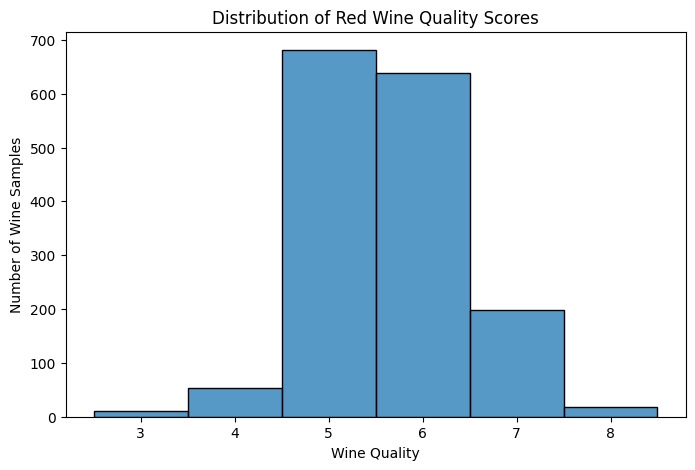

In [ ]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="quality", bins=6, discrete=True)

plt.title("Distribution of Red Wine Quality Scores")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wine Samples")
plt.xticks(range(3, 9))
plt.show()


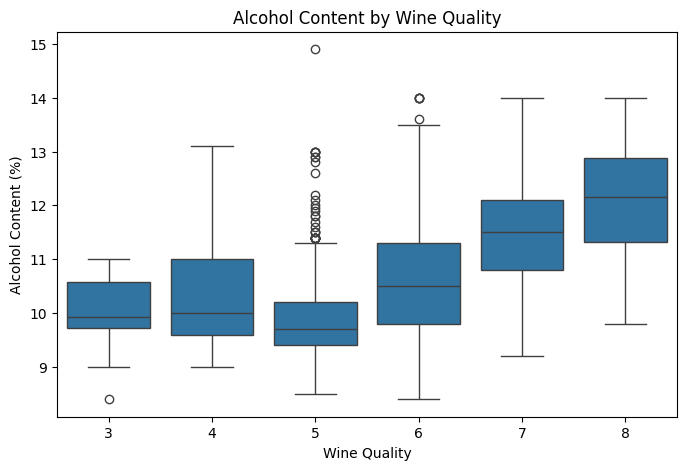

In [ ]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="quality", y="alcohol")

plt.title("Alcohol Content by Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Alcohol Content (%)")
plt.show()


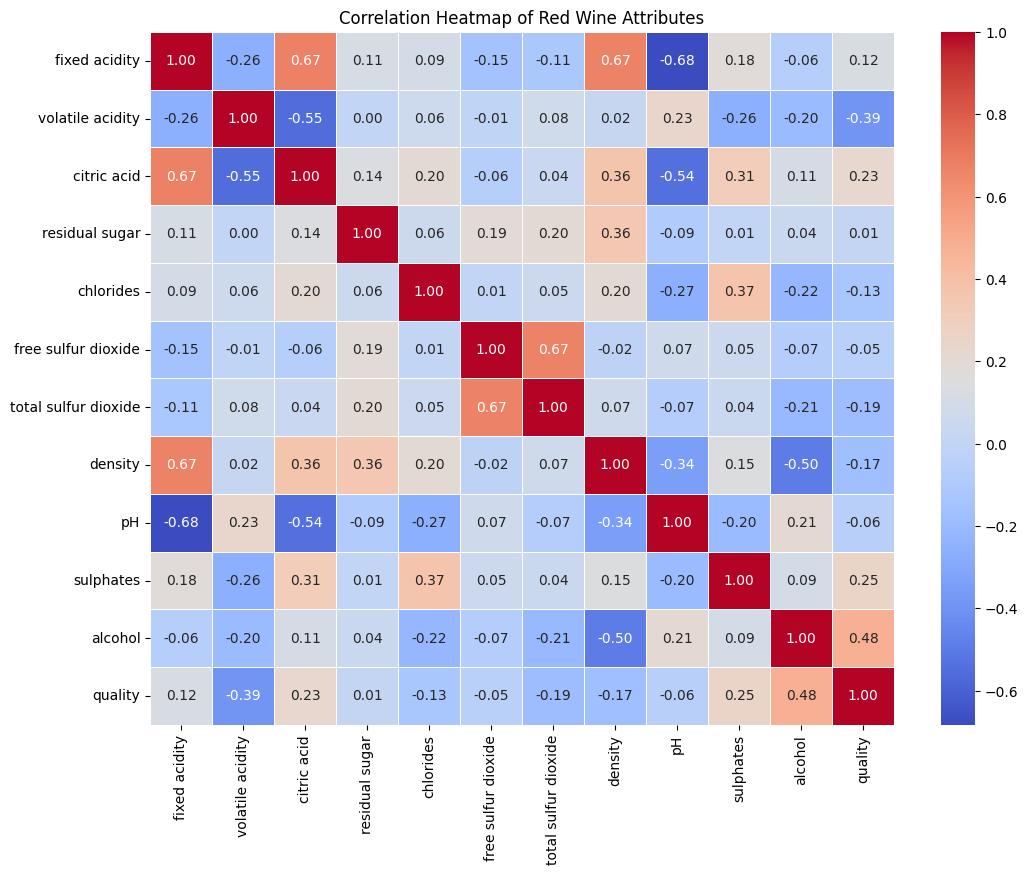

In [ ]:

plt.figure(figsize=(12, 9))

correlation_matrix = df.corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Red Wine Attributes")
plt.show()


In [ ]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression


In [ ]:

# Input features: 11 physicochemical attributes
X = df.drop(columns=["quality"])

# Target: wine quality score
y = df["quality"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (1599, 11)
Target shape: (1599,)


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (1279, 11)
Testing features: (320, 11)
Training target: (1279,)
Testing target: (320,)


In [ ]:

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [ ]:

y_pred = model.predict(X_test)

print("First 10 actual quality scores:")
print(y_test.head(10).to_list())

print("First 10 predicted quality scores:")
print(y_pred[:10])


First 10 actual quality scores:
[6, 5, 6, 5, 6, 5, 5, 5, 5, 6]
First 10 predicted quality scores:
[5.34666441 5.05631345 5.66446972 5.46451484 5.72518476 5.27928659
 5.03421667 5.12623347 5.74534288 5.68665032]


In [ ]:

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)


MAE: 0.5035304415524372
MSE: 0.3900251439639545
RMSE: 0.6245199307980126
R2 Score: 0.40318034127962254


# **WHITE WINE**

In [ ]:
df = pd.read_csv("winequality-white.csv", sep=";")
print(df.head())
print(df.shape)

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.0              0.27         0.36            20.7      0.045   
1            6.3              0.30         0.34             1.6      0.049   
2            8.1              0.28         0.40             6.9      0.050   
3            7.2              0.23         0.32             8.5      0.058   
4            7.2              0.23         0.32             8.5      0.058   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 45.0                 170.0   1.0010  3.00       0.45   
1                 14.0                 132.0   0.9940  3.30       0.49   
2                 30.0                  97.0   0.9951  3.26       0.44   
3                 47.0                 186.0   0.9956  3.19       0.40   
4                 47.0                 186.0   0.9956  3.19       0.40   

   alcohol  quality  
0      8.8        6  
1      9.5        6  
2     10.1        6 

In [ ]:
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nDescriptive Statistics:")
display(df.describe())

Dataset Shape: (4898, 12)

Data Types:
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total Missing Values:
0

Duplicate Rows:
937

Descriptive Statistics:


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [ ]:
print("Wine Quality Counts:")
print(df["quality"].value_counts().sort_index())

Wine Quality Counts:
quality
3      20
4     163
5    1457
6    2198
7     880
8     175
9       5
Name: count, dtype: int64


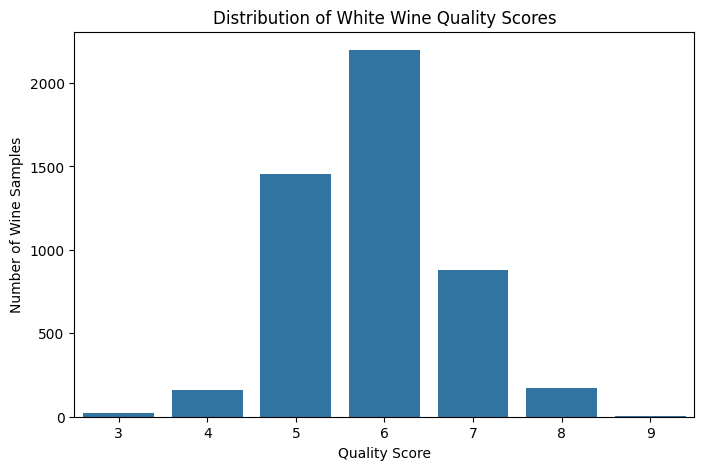

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="quality")

plt.title("Distribution of White Wine Quality Scores")
plt.xlabel("Quality Score")
plt.ylabel("Number of Wine Samples")
plt.show()

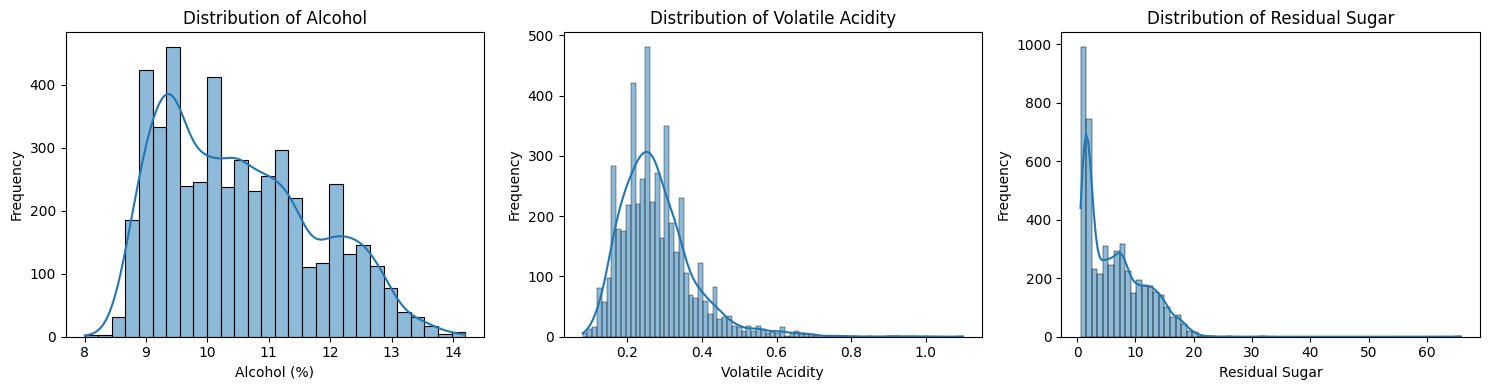

In [ ]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(data=df, x="alcohol", kde=True)
plt.title("Distribution of Alcohol")
plt.xlabel("Alcohol (%)")
plt.ylabel("Frequency")

plt.subplot(1, 3, 2)
sns.histplot(data=df, x="volatile acidity", kde=True)
plt.title("Distribution of Volatile Acidity")
plt.xlabel("Volatile Acidity")
plt.ylabel("Frequency")

plt.subplot(1, 3, 3)
sns.histplot(data=df, x="residual sugar", kde=True)
plt.title("Distribution of Residual Sugar")
plt.xlabel("Residual Sugar")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

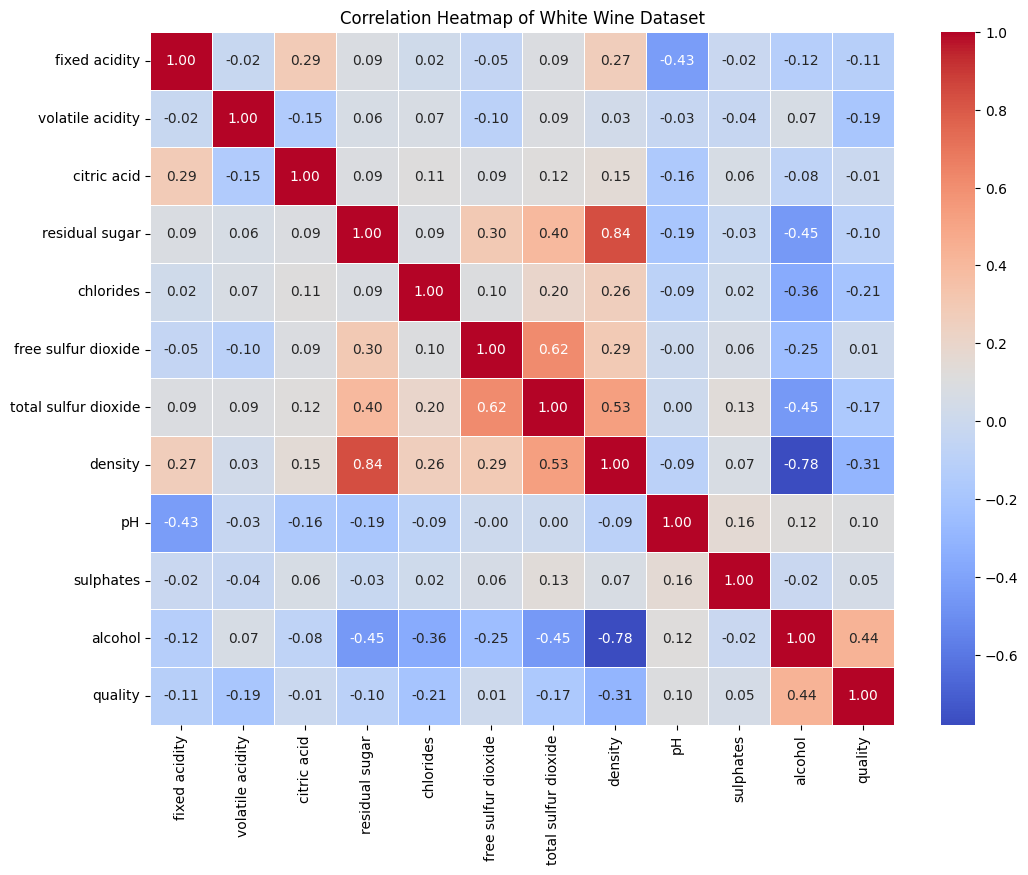

In [ ]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of White Wine Dataset")
plt.show()

In [ ]:
quality_correlation = correlation["quality"].drop("quality")

print("Correlation with Wine Quality:")
print(quality_correlation.sort_values(ascending=False))

Correlation with Wine Quality:
alcohol                 0.435575
pH                      0.099427
sulphates               0.053678
free sulfur dioxide     0.008158
citric acid            -0.009209
residual sugar         -0.097577
fixed acidity          -0.113663
total sulfur dioxide   -0.174737
volatile acidity       -0.194723
chlorides              -0.209934
density                -0.307123
Name: quality, dtype: float64


In [ ]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop("quality", axis=1)
y = df["quality"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (3918, 11)
Testing features: (980, 11)
Training target: (3918,)
Testing target: (980,)


In [ ]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")
print("Intercept:", model.intercept_)

print("\nRegression Coefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")

Model trained successfully!
Intercept: 124.39391498452245

Regression Coefficients:
fixed acidity: 0.0459
volatile acidity: -1.9149
citric acid: -0.0613
residual sugar: 0.0712
chlorides: -0.0265
free sulfur dioxide: 0.0051
total sulfur dioxide: -0.0002
density: -124.2641
pH: 0.6007
sulphates: 0.6491
alcohol: 0.2290


In [ ]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Predict wine quality
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("White Wine Model Evaluation")
print("----------------------------")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE):  {mse:.4f}")
print(f"Root Mean Squared Error:   {rmse:.4f}")
print(f"R-squared (R²):            {r2:.4f}")

White Wine Model Evaluation
----------------------------
Mean Absolute Error (MAE): 0.5863
Mean Squared Error (MSE):  0.5690
Root Mean Squared Error:   0.7543
R-squared (R²):            0.2653


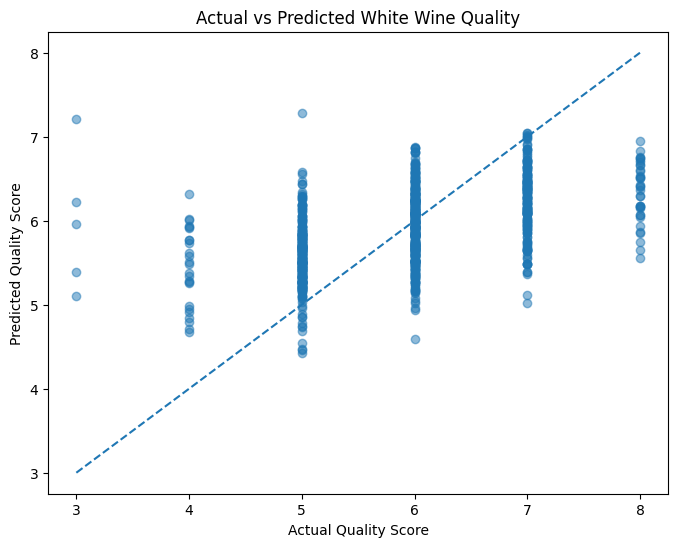

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Ideal prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted White Wine Quality")
plt.xlabel("Actual Quality Score")
plt.ylabel("Predicted Quality Score")
plt.show()

In [ ]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Standardize the training features
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)

# Standardize the target
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# Train regression using standardized data
standardized_model = LinearRegression()
standardized_model.fit(X_train_scaled, y_train_scaled)

# Display standardized coefficients
standardized_coefficients = pd.Series(
    standardized_model.coef_,
    index=X.columns
).sort_values(ascending=False)

print("Standardized Regression Coefficients:")
print(standardized_coefficients.round(4))

Standardized Regression Coefficients:
residual sugar          0.4128
alcohol                 0.3171
pH                      0.1017
free sulfur dioxide     0.0963
sulphates               0.0831
fixed acidity           0.0437
chlorides              -0.0007
citric acid            -0.0083
total sulfur dioxide   -0.0115
volatile acidity       -0.2194
density                -0.4234
dtype: float64
